# Predicting NBA Success Based on Rookie Stats

This notebook represents my workflow and data science techniques in building a sufficent classification model for our target.

Separate Notebook to compare the difference with a 3 Tier Classification Model

Author: Rasheed Martin

In [1]:
import polars as pl
from pathlib import Path
# Load the data
path = Path.cwd().parent.parent / "data/refined_raw_data" /  "Player_Type_Modeling" / "player_3tier_label_with_target_all_years.csv"
df = pl.read_csv(path)
df

Player,Season,Player_Age,2P,2P%,2PA,3P,3P%,3PA,3PAr,AST,AST%,BLK,BLK%,BPM,DBPM,DRB,DRB%,DWS,FG,FG%,FGA,FT,FT%,FTA,FTr,G,GS,MP,OBPM,ORB,ORB%,OWS,PER,PF,PTS,STL,…,FT%_third,FTA_third,FTr_third,G_third,GS_third,MP_third,OBPM_third,ORB_third,ORB%_third,OWS_third,PER_third,PF_third,PTS_third,Player_Age_third,STL_third,STL%_third,TOV_third,TOV%_third,TRB_third,TRB%_third,TS%_third,Trp-Dbl_third,USG%_third,VORP_third,WS_third,WS/48_third,eFG%_third,All_Nba_Team_Max,AllStar_Max,Games_Played_Mean,Win_Share_Sum,Box_Plus_Minus_Mean,Minutes_Played_Mean,Games_Started_Mean,Usage_Mean,Player_Score,Player_Label
str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,f64,str
"""AC. Green""",2000,37.0,144.0,0.453,318.0,0.0,0.0,6.0,0.019,39.0,4.8,8.0,0.4,-2.2,0.0,206.0,17.3,2.1,144.0,0.444,324.0,79.0,0.712,111.0,0.343,82.0,1.0,1411.0,-2.2,107.0,9.0,1.1,11.2,119.0,367.0,30.0,…,0.712,111.0,0.343,82.0,1.0,1411.0,-2.2,107.0,9.0,1.1,11.2,119.0,367.0,37.0,30.0,1.2,45.0,10.8,313.0,13.2,0.492,0.0,14.4,-0.1,3.2,0.11,0.444,0,false,82.0,3.2,-2.2,1411.0,1.0,14.4,0.2928397,"""Bust Player"""
"""AJ Griffin""",2022,19.0,147.0,0.536,274.0,101.0,0.39,259.0,0.486,73.0,7.0,12.0,0.7,-0.8,-0.5,116.0,9.2,0.9,248.0,0.465,533.0,42.0,0.894,47.0,0.088,72.0,12.0,1401.0,-0.3,37.0,2.9,1.3,12.6,87.0,639.0,42.0,…,1.0,2.0,0.032,20.0,0.0,171.0,-6.0,2.0,1.2,-0.4,1.2,6.0,48.0,20.0,1.0,0.3,8.0,11.3,18.0,5.7,0.382,0.0,17.3,-0.3,-0.4,-0.12,0.371,0,false,46.0,1.8000001,-5.2,786.0,6.0,17.599998,0.289669,"""Bust Player"""
"""AJ Johnson""",2024,20.0,58.0,0.472,123.0,24.0,0.267,90.0,0.423,76.0,17.1,3.0,0.4,-8.1,-2.5,51.0,8.3,0.0,82.0,0.385,213.0,32.0,0.865,37.0,0.174,29.0,11.0,639.0,-5.6,8.0,1.3,-0.5,7.1,50.0,220.0,12.0,…,0.865,37.0,0.174,29.0,11.0,639.0,-5.6,8.0,1.3,-0.5,7.1,50.0,220.0,20.0,12.0,0.9,35.0,13.2,59.0,4.8,0.48,0.0,17.4,-1.0,-0.4,-0.032,0.441,0,false,29.0,-1.2,-8.1,639.0,11.0,17.4,0.281323,"""Bust Player"""
"""AJ. Green""",2022,23.0,9.0,0.45,20.0,44.0,0.419,105.0,0.84,22.0,8.7,0.0,0.0,-0.9,-0.6,39.0,11.3,0.3,53.0,0.424,125.0,4.0,1.0,4.0,0.032,35.0,1.0,345.0,-0.3,6.0,1.9,0.5,11.5,31.0,154.0,6.0,…,0.815,27.0,0.064,73.0,7.0,1659.0,-1.7,18.0,1.2,1.6,9.2,157.0,541.0,25.0,37.0,1.1,40.0,8.4,174.0,5.7,0.621,0.0,12.6,-0.1,2.8,0.082,0.612,0,false,54.666668,4.7,-1.733333,872.6667,2.6666667,14.8,0.285053,"""Bust Player"""
"""AJ. Guyton""",2000,22.0,51.0,0.415,123.0,27.0,0.391,69.0,0.359,64.0,18.1,5.0,0.6,-4.0,-3.2,26.0,5.1,-0.1,78.0,0.406,192.0,15.0,0.833,18.0,0.094,33.0,8.0,630.0,-0.8,10.0,1.8,0.4,10.3,35.0,198.0,9.0,…,null,0.0,0.0,2.0,0.0,9.0,-14.1,0.0,0.0,-0.1,-9.0,0.0,0.0,24.0,1.0,5.7,1.0,20.0,0.0,0.0,0.0,0.0,23.6,0.0,-0.1,-0.45,0.0,0,false,26.666666,0.3,-7.333334,415.33334,4.6666665,20.766668,0.2819847,"""Bust Player"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""Zoran Dragic""",2014,25.0,8.0,0.5,16.0,3.0,0.214,14.0,0.467,5.0,11.2,0.0,0.0,-7.7,-3.6,3.0,4.6,0.0,11.0,0.367,30.0,3.0,0.6,5.0,0.167,16.0,1.0,75.0,-4.1,5.0,7.8,-0.1,8.2,6.0,28.0,2.0,…,0.6,5.0,0.167,16.0,1.0,75.0,-4.1,5.0,7.8,-0.1,8.2,6.0,28.0,25.0,2.0,1.4,5.0,13.4,8.0,6.2,0.435,0.0,22.9,-0.1,-0.1,-0.042,0.417,0,false,16.0,-0.1,-7.7,75.0,1.0,22.9,0.271411,"""Bust Player"""
"""Zoran Planinic""",2003,21.0,44.0,0.454,97.0,9.0,0.281,32.0,0.248,68.0,23.9,3.0,0.5,-3.4,-0.1,41.0,10.2,0.6,53.0,0.411,129.0,38.0,0.633,60.0,0.465,49.0,1.0,473.0,-3.3,14.0,3.5,0.1,10.0,70.0,153.0,13.0,…,0.697,66.0,0.361,56.0,1.0,596.0,-6.1,14.0,2.7,-0.8,6.9,91.0,191.0,23.0,20.0,1.8,43.0,16.9,74.0,7.3,0.45,0.0,20.2,-0.6,0.1,0.005,0.396,0,false,49.333332,1.6,-3.366667,528.0,3.3333333,20.466667,0.295539,"""Bust Player"""
"""Zydrunas Ilgauskas""",2000,25.0,114.0,0.491,232.0,0.0,0.0,2.0,0.009,18.0,5.4,37.0,4.4,-1.8,-0.4,9

## Import the Transformer
We have already did our feature selection and preprocessing. So we will just import the transformer and run some models

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from pipeline import print_metrics, pipeline
from pipeline import print_roc_curve, print_precision_recall_curve


X = df.drop("Player_Label")
y = df["Player_Label"]

# Outside the pipeline
player_label_order = [["Bust Player", "Role Player", "Star Player"]]
player_label_encoder = OrdinalEncoder(categories=player_label_order)

y = player_label_encoder.fit_transform(df[["Player_Label"]]).flatten()
target_names=player_label_encoder.categories_[0] 

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

X_train_processed = pipeline().fit_transform(X_train)
X_test_processed = pipeline().fit_transform(X_test)

### Random Forest

              precision    recall  f1-score   support

 Bust Player       0.89      0.90      0.89       249
 Role Player       0.66      0.68      0.67       137
 Star Player       0.83      0.77      0.80       110

    accuracy                           0.81       496
   macro avg       0.79      0.78      0.79       496
weighted avg       0.81      0.81      0.81       496

Accuracy: 0.8104838709677419
Precision (macro): 0.7927610984965286
Recall (macro): 0.7837192610299638
F1 Score (macro): 0.7877939398462437


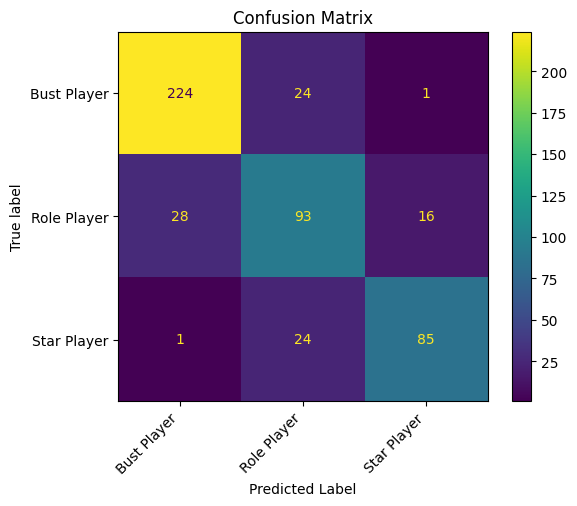

In [ ]:
from sklearn.ensemble import RandomForestClassifier


model = RandomForestClassifier(random_state=42)
model.fit(X_train_processed, y_train)
y_pred = model.predict(X_test_processed)
print_metrics(y_test, y_pred, target_names)
print_roc_curve(y_test, model, X_test_processed, target_names)
print_precision_recall_curve(y_test, model, X_test_processed, target_names)

### XGB

/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/xgboost/training.py:183: UserWarning: [02:33:38] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


              precision    recall  f1-score   support

 Bust Player       0.89      0.92      0.90       249
 Role Player       0.67      0.65      0.66       137
 Star Player       0.78      0.76      0.77       110

    accuracy                           0.81       496
   macro avg       0.78      0.78      0.78       496
weighted avg       0.81      0.81      0.81       496

Accuracy: 0.8084677419354839
Precision (macro): 0.7803561190558095
Recall (macro): 0.7763113502450412
F1 Score (macro): 0.7782211219520088


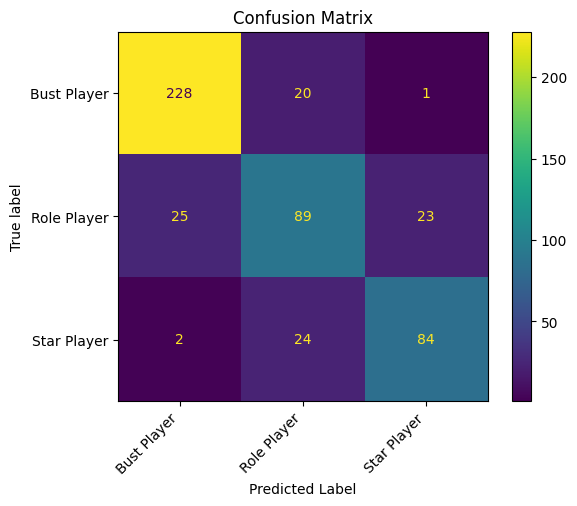

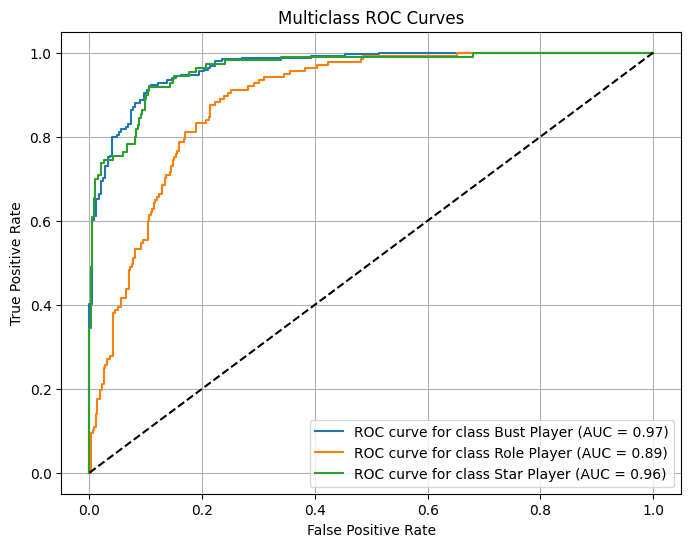

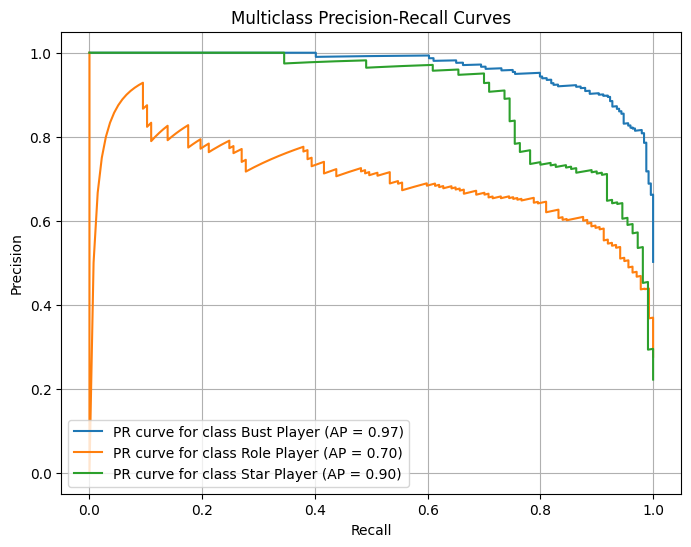

In [6]:
from xgboost import XGBClassifier

model = XGBClassifier(use_label_encoder=True, eval_metric='mlogloss')
model.fit(X_train_processed, y_train)
preds = model.predict(X_test_processed)
print_metrics(y_test, preds, target_names)
print_roc_curve(y_test, model, X_test_processed, target_names)
print_precision_recall_curve(y_test, model, X_test_processed, target_names)

/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/xgboost/training.py:183: UserWarning: [02:37:11] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Fold 1 Report
              precision    recall  f1-score   support

 Bust Player       0.91      0.93      0.92       249
 Role Player       0.68      0.70      0.69       137
 Star Player       0.80      0.74      0.77       110

    accuracy                           0.82       496
   macro avg       0.80      0.79      0.79       496
weighted avg       0.82      0.82      0.82       496

Accuracy: 0.8225806451612904
Precision (macro): 0.797426693582409
Recall (macro): 0.7882681355814766
F1 Score (macro): 0.7923030198230306


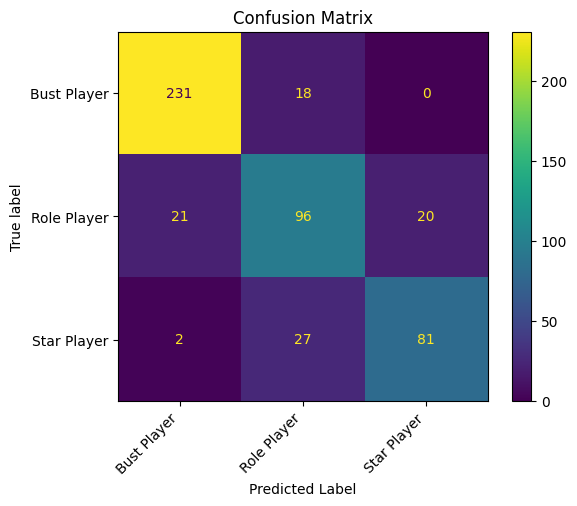

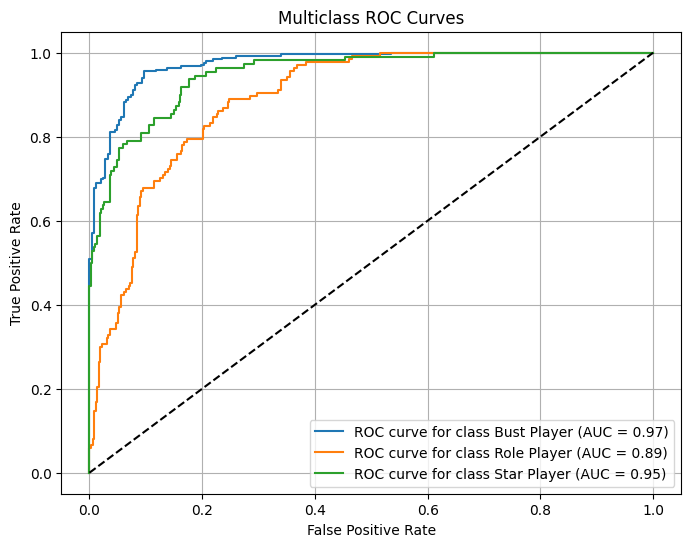

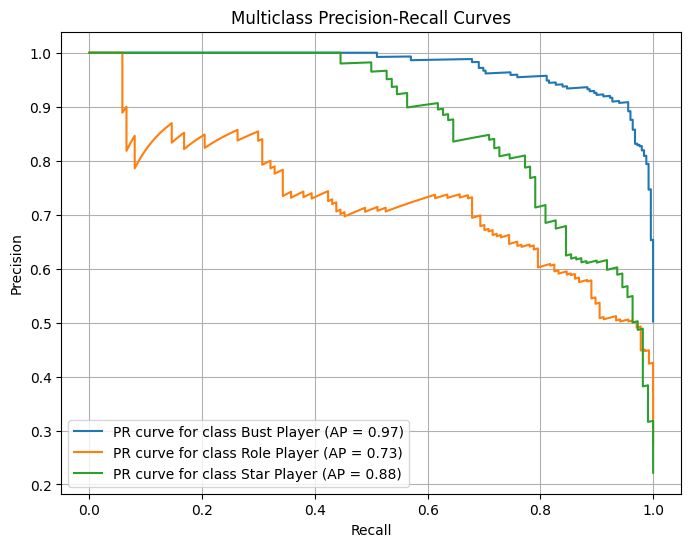

/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/xgboost/training.py:183: UserWarning: [02:37:12] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Fold 2 Report
              precision    recall  f1-score   support

 Bust Player       0.87      0.92      0.89       249
 Role Player       0.67      0.65      0.66       136
 Star Player       0.87      0.79      0.83       110

    accuracy                           0.82       495
   macro avg       0.80      0.79      0.79       495
weighted avg       0.81      0.82      0.81       495

Accuracy: 0.8161616161616162
Precision (macro): 0.803720858777893
Recall (macro): 0.7869945020724609
F1 Score (macro): 0.7944585110163468


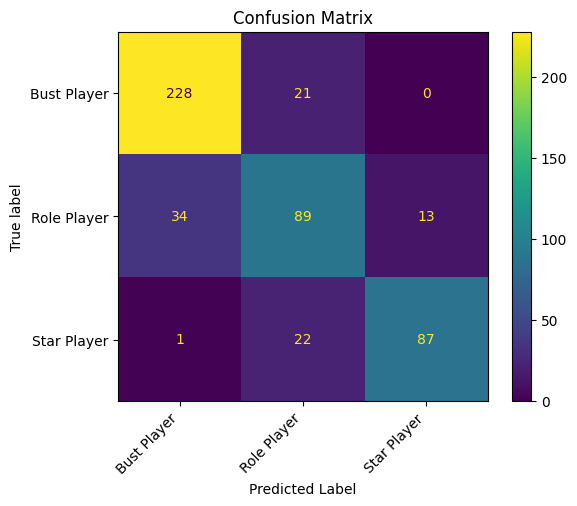

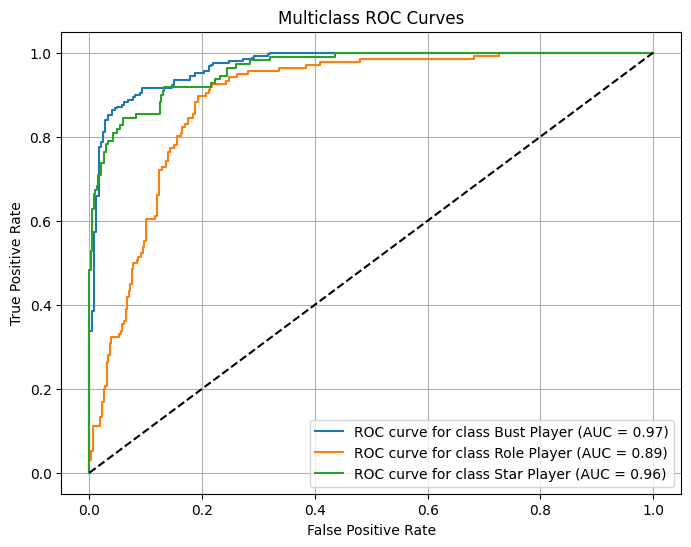

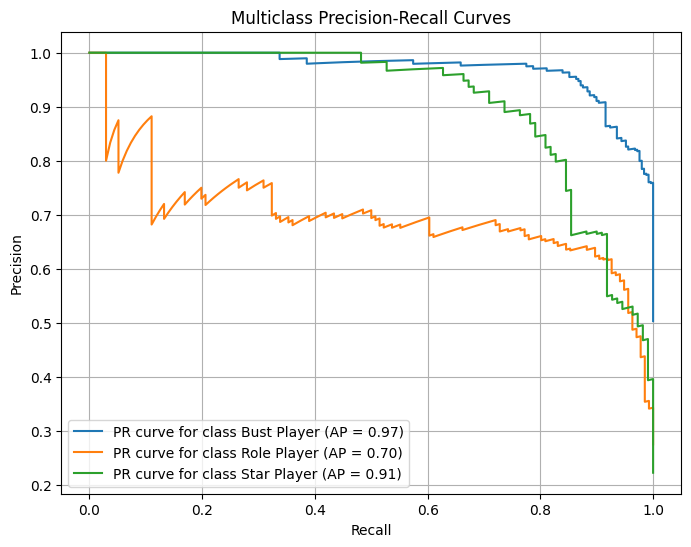

/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/xgboost/training.py:183: UserWarning: [02:37:13] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Fold 3 Report
              precision    recall  f1-score   support

 Bust Player       0.91      0.94      0.92       249
 Role Player       0.68      0.70      0.69       136
 Star Player       0.82      0.73      0.77       110

    accuracy                           0.82       495
   macro avg       0.80      0.79      0.79       495
weighted avg       0.82      0.82      0.82       495

Accuracy: 0.8242424242424242
Precision (macro): 0.8005042483919639
Recall (macro): 0.7871817036416612
F1 Score (macro): 0.7928617276443363


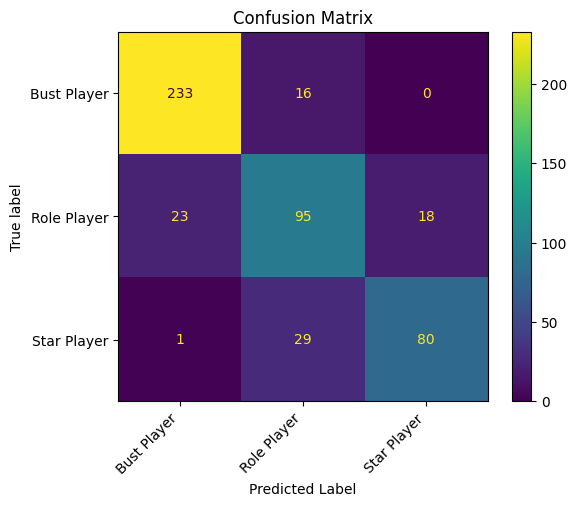

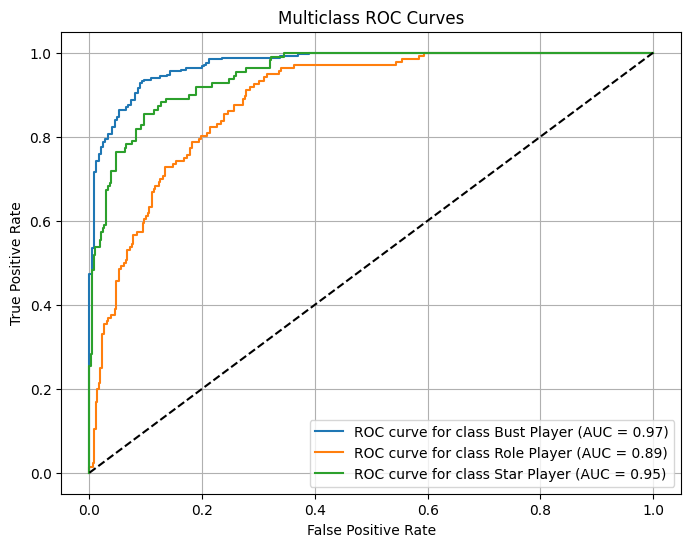

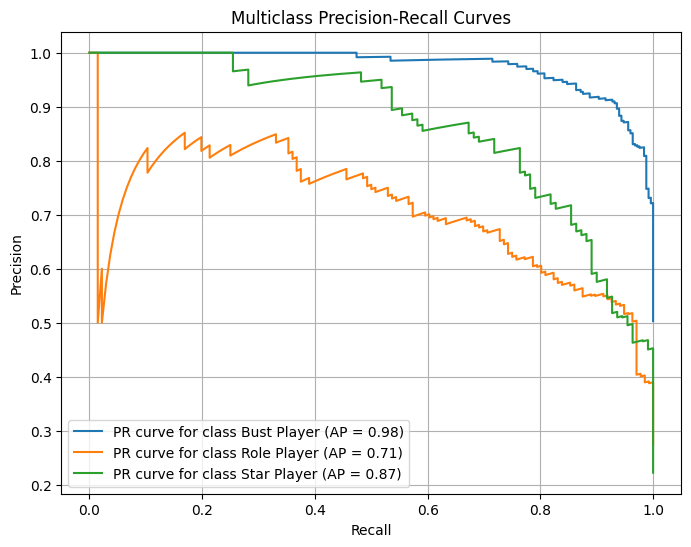

/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/xgboost/training.py:183: UserWarning: [02:37:14] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Fold 4 Report
              precision    recall  f1-score   support

 Bust Player       0.91      0.92      0.92       249
 Role Player       0.66      0.68      0.67       136
 Star Player       0.77      0.71      0.74       110

    accuracy                           0.81       495
   macro avg       0.78      0.77      0.78       495
weighted avg       0.81      0.81      0.81       495

Accuracy: 0.8101010101010101
Precision (macro): 0.7803142016329293
Recall (macro): 0.7722030725397132
F1 Score (macro): 0.7757170995499697


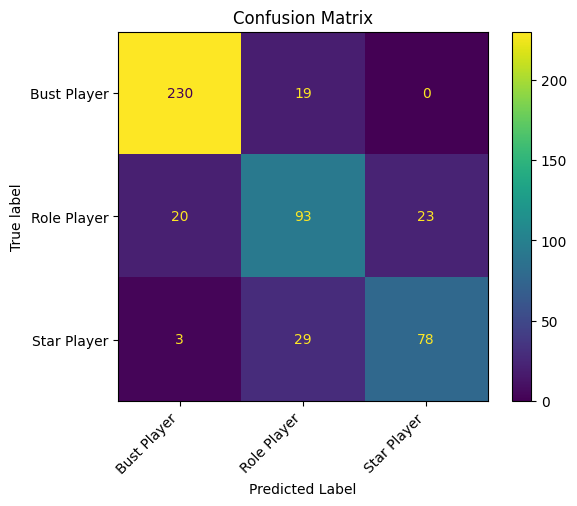

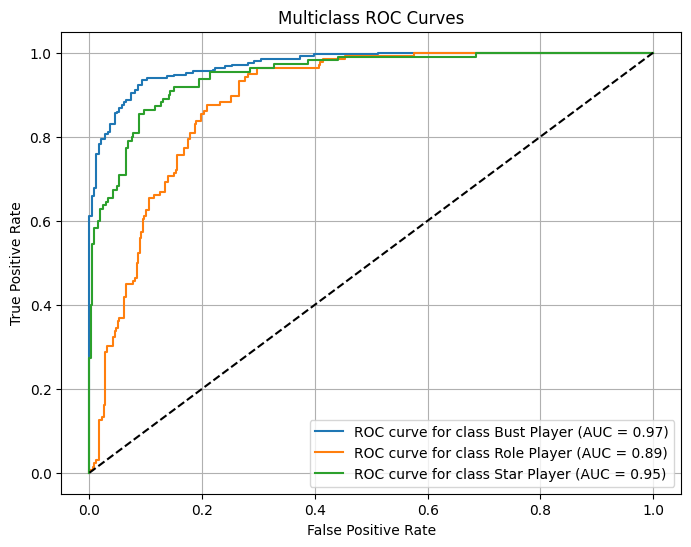

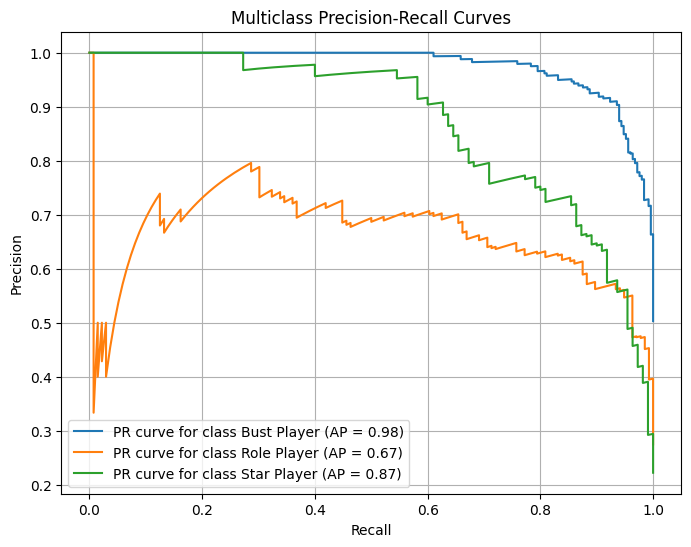

/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/xgboost/training.py:183: UserWarning: [02:37:14] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Fold 5 Report
              precision    recall  f1-score   support

 Bust Player       0.91      0.91      0.91       248
 Role Player       0.67      0.71      0.69       137
 Star Player       0.82      0.76      0.79       110

    accuracy                           0.82       495
   macro avg       0.80      0.79      0.80       495
weighted avg       0.82      0.82      0.82       495

Accuracy: 0.8222222222222222
Precision (macro): 0.8001451380914268
Recall (macro): 0.794318627765767
F1 Score (macro): 0.7968047253405252


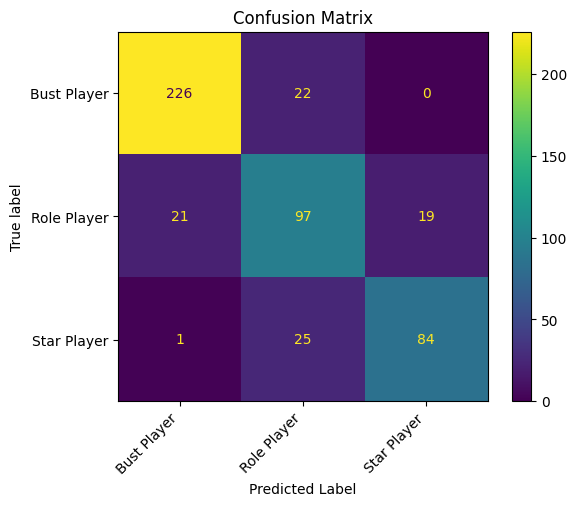

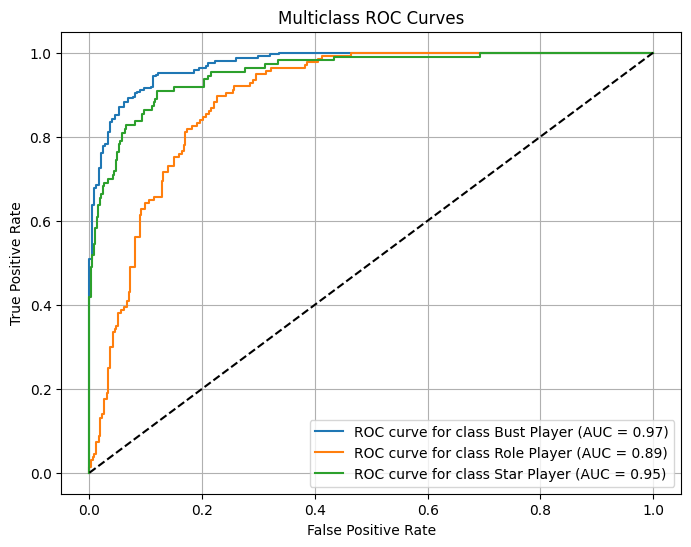

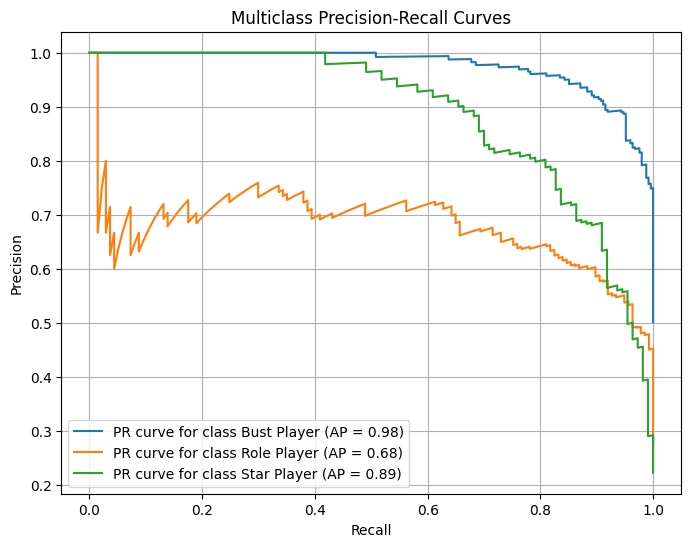

In [8]:
from sklearn.model_selection import StratifiedKFold
import numpy as np

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

X_np = X.to_pandas()  # Convert Polars DataFrame to pandas for compatibility with preprocessor
for fold, (train_idx, test_idx) in enumerate(skf.split(X_np, y)):
    X_train, X_test = X_np.iloc[train_idx], X_np.iloc[test_idx]
    y_train, y_test = np.array(y)[train_idx], np.array(y)[test_idx]

    transformer = pipeline()
    X_train_processed = transformer.fit_transform(X_train)
    X_test_processed = transformer.transform(X_test)

    model.fit(X_train_processed, y_train)
    preds = model.predict(X_test_processed)
    
    print(f"Fold {fold + 1} Report")
    print_metrics(y_test, preds, target_names)
    print_roc_curve(y_test, model, X_test_processed, target_names)
    print_precision_recall_curve(y_test, model, X_test_processed, target_names)
    print("\n" + "="*50 + "\n")

## Logistic Regression

/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


              precision    recall  f1-score   support

 Bust Player       0.91      0.90      0.91       248
 Role Player       0.69      0.77      0.72       137
 Star Player       0.88      0.77      0.82       110

    accuracy                           0.84       495
   macro avg       0.83      0.81      0.82       495
weighted avg       0.84      0.84      0.84       495

Accuracy: 0.8363636363636363
Precision (macro): 0.8256162946278168
Recall (macro): 0.8141254789477065
F1 Score (macro): 0.8180386930717648


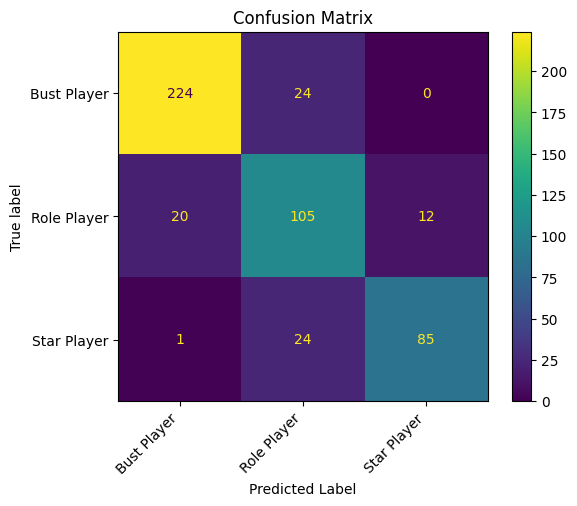

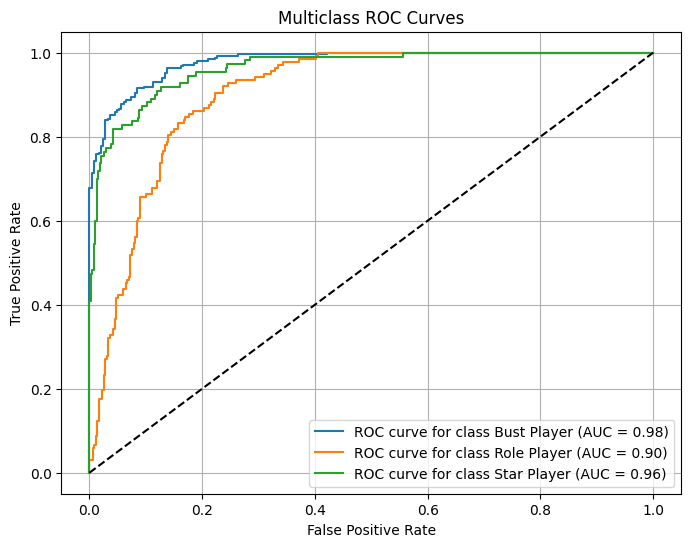

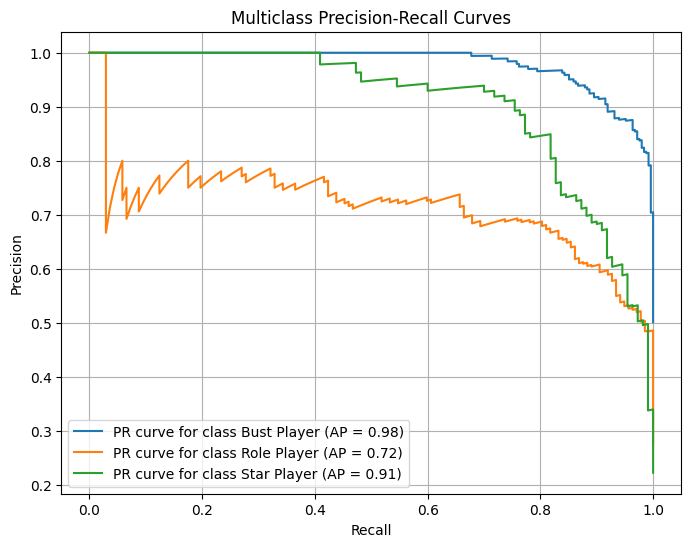

In [9]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    multi_class='multinomial', 
    max_iter=1000,
    solver='saga',
    random_state=42,
    penalty='l2',
)
model.fit(X_train_processed, y_train)
preds = model.predict(X_test_processed)
print_metrics(y_test, preds, target_names)
print_roc_curve(y_test, model, X_test_processed, target_names)
print_precision_recall_curve(y_test, model, X_test_processed, target_names)

In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

# Random Forest Classifier with cross-validation
rf = RandomForestClassifier(random_state=42)

scores = cross_val_score(rf, X_train_processed, y_train, cv=5, scoring='accuracy')
print("RF CV Accuracy scores:", scores)
print("RF Mean CV Accuracy:", scores.mean())

# XGBoost Classifier with cross-validation
xgb = XGBClassifier(random_state=42)

scores = cross_val_score(xgb, X_train_processed, y_train, cv=5, scoring='accuracy')
print("XGB CV Accuracy scores:", scores)
print("XGB Mean CV Accuracy:", scores.mean())

# Logistic Regression Classifier with cross-validation
lr = LogisticRegression(random_state=42)

scores = cross_val_score(lr, X_train_processed, y_train, cv=5, scoring='accuracy')
print("LR CV Accuracy scores:", scores)
print("LR Mean CV Accuracy:", scores.mean())

RF CV Accuracy scores: [0.83375315 0.84343434 0.81060606 0.80555556 0.80050505]
RF Mean CV Accuracy: 0.8187708317431239
XGB CV Accuracy scores: [0.82115869 0.83838384 0.82575758 0.80555556 0.79292929]
XGB Mean CV Accuracy: 0.816756990560517
LR CV Accuracy scores: [0.84634761 0.86111111 0.83080808 0.84848485 0.80555556]
LR Mean CV Accuracy: 0.8384614406024985


Our best model is Logistic Regression with ~83% accuracy. Next, we will tune it using RandomizedSearch.

In [12]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from scipy.stats import loguniform

param_dist = {
    'C': loguniform(1e-4, 1e2),
    'penalty': ['l2'],
    'solver': ['saga', 'lbfgs'],
    'max_iter': [500, 1000, 2000],
    'multi_class': ['multinomial']
}

lr = LogisticRegression(random_state=42)
search = RandomizedSearchCV(
    lr,
    param_distributions=param_dist,
    n_iter=50,
    cv=5,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1,
    verbose=2
)

search.fit(X_train_processed, y_train)

print("Best params:", search.best_params_)
print("Best CV score:", search.best_score_)

Fitting 5 folds for each of 50 candidates, totalling 250 fits


/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/ras

[CV] END C=0.0008632008168602544, max_iter=2000, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.0s
[CV] END C=0.0008632008168602544, max_iter=2000, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.0s
[CV] END C=0.017670169402947963, max_iter=500, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.0s
[CV] END C=0.017670169402947963, max_iter=500, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.0s
[CV] END C=0.017670169402947963, max_iter=500, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.0s
[CV] END C=0.017670169402947963, max_iter=500, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.0s
[CV] END C=0.017670169402947963, max_iter=500, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.0s
[CV] END C=0.0008632008168602544, max_iter=2000, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.0s
[CV] END C=0.00022310108018679258, max_iter=500, multi_class=multi

/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it w

[CV] END C=0.01971387269004537, max_iter=500, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.0s
[CV] END C=2.465832945854912, max_iter=500, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.2s
[CV] END C=44.99979487472008, max_iter=1000, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=44.99979487472008, max_iter=1000, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=2.465832945854912, max_iter=500, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.2s
[CV] END C=0.020535203701049935, max_iter=1000, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.0s
[CV] END C=44.99979487472008, max_iter=1000, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=0.020535203701049935, max_iter=1000, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.0s
[CV] END C=2.465832945854912, max_iter=500, multi_class=multinomial, penalty=l2,

/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/ras

... (12 outputs left out)

[CV] END C=0.4231596757398785, max_iter=2000, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.1s
[CV] END C=0.4231596757398785, max_iter=2000, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.2s
[CV] END C=0.4231596757398785, max_iter=2000, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.2s
[CV] END C=23.386439256208728, max_iter=1000, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.5s
[CV] END C=33.981724150105975, max_iter=1000, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.4s
[CV] END C=15.087613675681679, max_iter=1000, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.4s


/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it w

[CV] END C=14.442502135125398, max_iter=2000, multi_class=multinomial, penalty=l2, solver=saga; total time=   1.1s
[CV] END C=14.442502135125398, max_iter=2000, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.9s
[CV] END C=23.386439256208728, max_iter=1000, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.4s
[CV] END C=33.981724150105975, max_iter=1000, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.4s
[CV] END C=15.087613675681679, max_iter=1000, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.4s
Best params: {'C': np.float64(0.4689400963537689), 'max_iter': 1000, 'multi_class': 'multinomial', 'penalty': 'l2', 'solver': 'lbfgs'}
Best CV score: 0.841994249802814


/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1

              precision    recall  f1-score   support

 Bust Player       0.91      0.91      0.91       248
 Role Player       0.69      0.76      0.72       137
 Star Player       0.87      0.77      0.82       110

    accuracy                           0.84       495
   macro avg       0.82      0.81      0.82       495
weighted avg       0.84      0.84      0.84       495

Accuracy: 0.8363636363636363
Precision (macro): 0.8235742689904261
Recall (macro): 0.8130364749448807
F1 Score (macro): 0.8168203628729943


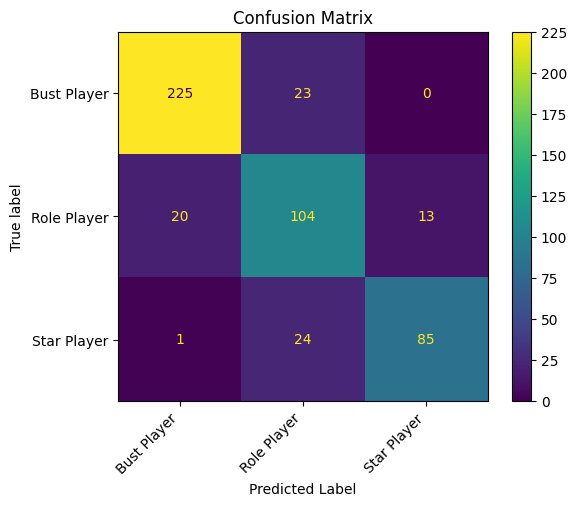

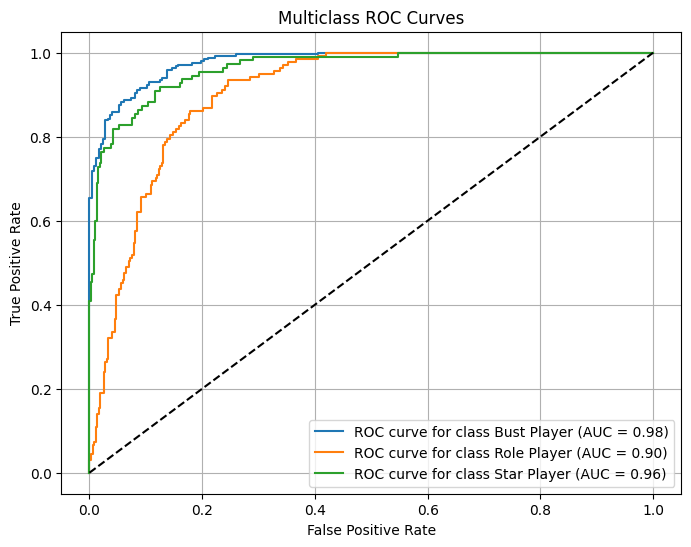

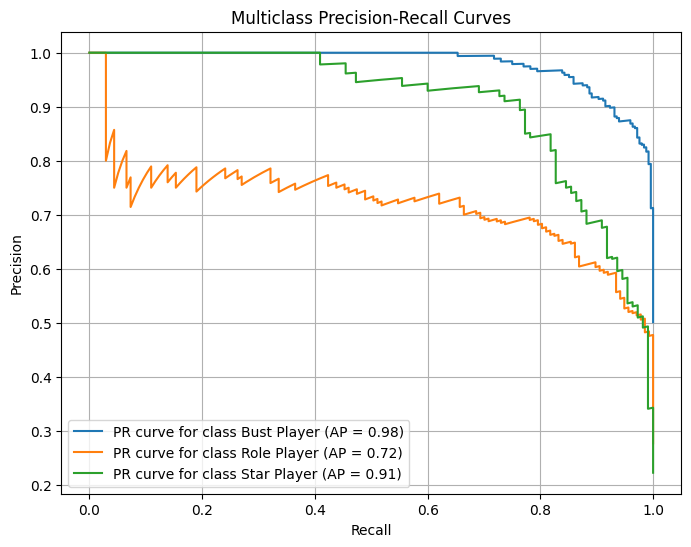

In [14]:
best_model = search.best_estimator_ 

y_pred = best_model.predict(X_test_processed)
print_metrics(y_test, y_pred, target_names)
print_roc_curve(y_test, best_model, X_test_processed, target_names)
print_precision_recall_curve(y_test, best_model, X_test_processed, target_names)

### Grid Search

Performing grid search to optimize hyperparameters for Logistic Regression.

In [13]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l2'],
    'solver': ['saga', 'lbfgs'],
    'max_iter': [500, 1000, 2000],
    'multi_class': ['multinomial']
}

lr = LogisticRegression(random_state=42)
grid = GridSearchCV(
    lr,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=2
)

grid.fit(X_train_processed, y_train)
print("Best params:", grid.best_params_)


Fitting 5 folds for each of 30 candidates, totalling 150 fits
[CV] END C=0.01, max_iter=500, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.0s
[CV] END C=0.01, max_iter=500, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=0.01, max_iter=500, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.0s
[CV] END C=0.01, max_iter=500, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=0.01, max_iter=500, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=0.01, max_iter=500, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.0s
[CV] END C=0.01, max_iter=500, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=0.01, max_iter=500, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=0.01, max_iter=500, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.0s
[CV] END C=0.01, max_iter=500, mu

/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/ras

[CV] END C=1, max_iter=1000, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=1, max_iter=2000, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=1, max_iter=1000, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=10, max_iter=500, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=1, max_iter=2000, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=10, max_iter=500, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=10, max_iter=500, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=10, max_iter=500, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=10, max_iter=1000, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=1, max_iter=500, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.3s
[CV] END C=

/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/ras

[CV] END C=10, max_iter=500, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.3s
[CV] END C=1, max_iter=1000, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.3s
[CV] END C=1, max_iter=1000, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.3s
[CV] END C=1, max_iter=2000, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.3s
[CV] END C=10, max_iter=500, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.3s
[CV] END C=1, max_iter=2000, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.3s
[CV] END C=1, max_iter=2000, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=1, max_iter=2000, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=1, max_iter=2000, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=10, max_iter=2000, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=10, 

/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it w

... (8 outputs left out)

[CV] END C=100, max_iter=2000, multi_class=multinomial, penalty=l2, solver=saga; total time=   1.0s
[CV] END C=100, max_iter=2000, multi_class=multinomial, penalty=l2, solver=saga; total time=   1.0s
[CV] END C=10, max_iter=2000, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.9s
[CV] END C=10, max_iter=2000, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.7s
[CV] END C=10, max_iter=2000, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s


/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Best params: {'C': 100, 'max_iter': 2000, 'multi_class': 'multinomial', 'penalty': 'l2', 'solver': 'saga'}


/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


              precision    recall  f1-score   support

 Bust Player       0.91      0.91      0.91       248
 Role Player       0.69      0.77      0.73       137
 Star Player       0.88      0.77      0.82       110

    accuracy                           0.84       495
   macro avg       0.83      0.82      0.82       495
weighted avg       0.84      0.84      0.84       495

Accuracy: 0.8383838383838383
Precision (macro): 0.8272374266064961
Recall (macro): 0.8154695649692117
F1 Score (macro): 0.8196102704507763


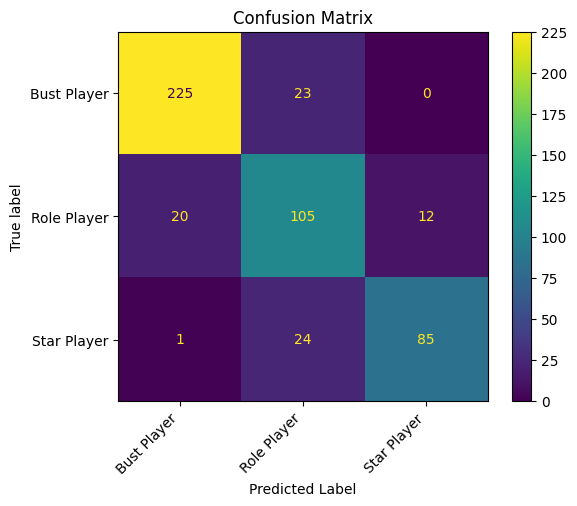

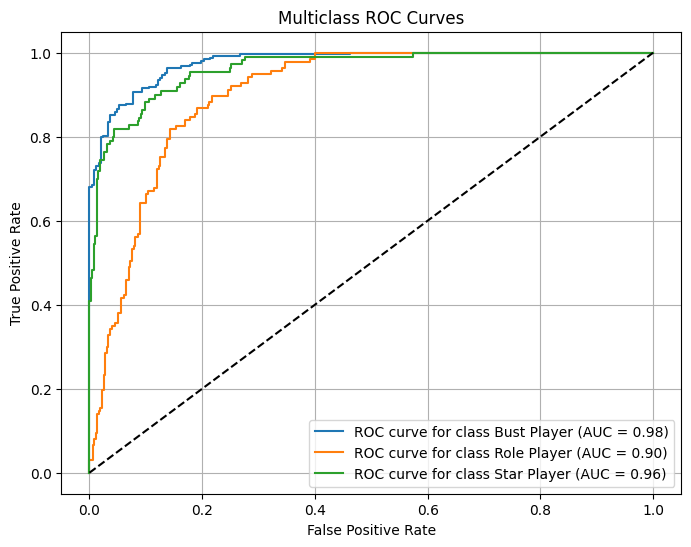

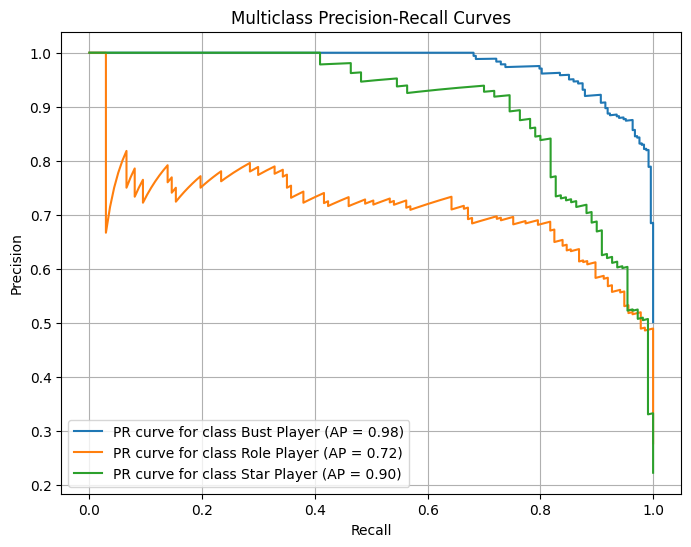

In [15]:
best_model = grid.best_estimator_  # or grid.best_estimator_

y_pred = best_model.predict(X_test_processed)
print_metrics(y_test, y_pred, target_names)
print_roc_curve(y_test, best_model, X_test_processed, target_names)
print_precision_recall_curve(y_test, best_model, X_test_processed, target_names)

## Save the Best Model

Save the best trained model to disk for future use.

In [17]:
import joblib
# Save the model
model_path = Path.cwd().parent / "models"
model_path.mkdir(exist_ok=True, parents=True)
joblib.dump(best_model, model_path / "logistic_regression_model.pkl")

['/Users/rashe/PycharmProjects/PredictingNBACareers/notebooks/models/logistic_regression_model.pkl']